# Assignment 52 — Week 5, Day 3
## Topic: Machine Learning — Logistic Regression

**Objective:** Perform logistic regression.

**Reference:** https://towardsdatascience.com/logistic-regression-using-python-sklearn-numpy-mnist-handwriting-recognition-matplotlib-a6b31e2b166a  
https://www.datacamp.com/community/tutorials/understanding-logistic-regression-python

Logistic regression is a **classification** algorithm: instead of predicting a number, it predicts the probability that an example belongs to a class, then picks the class.

This notebook has two parts, one for each reference:

1. **Handwritten digit recognition** (Towards Data Science) – multi-class classification of the digits 0–9.
2. **Diabetes prediction** (DataCamp) – binary classification on the Pima Indians Diabetes data set (`diabetes.csv`, which must be in the same folder).

**Diagram:** The sigmoid function turns any value into a probability between 0 and 1.

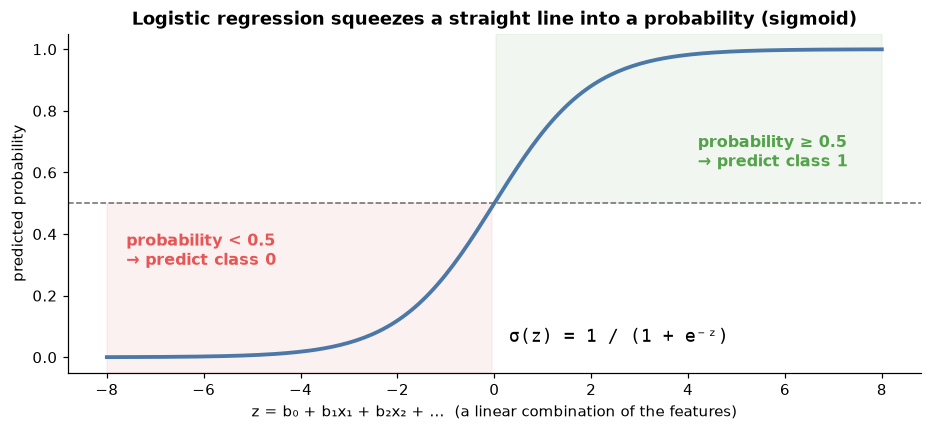

# Part 1 — Handwritten digit recognition

**Load the digits dataset**

In [1]:
from sklearn.datasets import load_digits

digits = load_digits()

print("Image data shape:", digits.data.shape)
print("Label data shape:", digits.target.shape)

Image data shape: (1797, 64)
Label data shape: (1797,)


**Explanation:** load_digits() is a dataset built into scikit-learn with 1797 images of handwritten digits (0–9). Each image is 8×8 pixels, stored as a row of 64 values.

**Show some of the images and their labels**

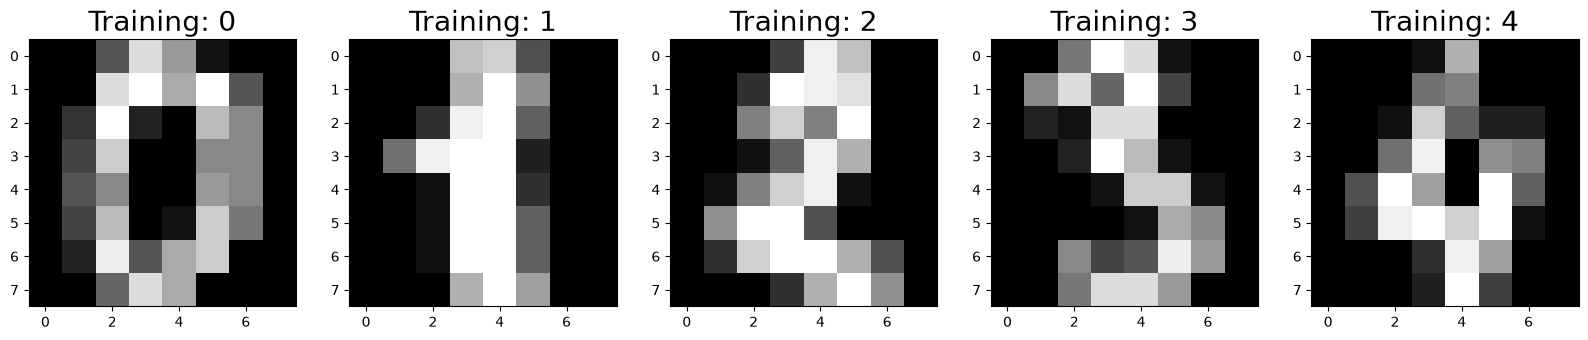

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

plt.figure(figsize=(20, 4))
for index, (image, label) in enumerate(zip(digits.data[0:5], digits.target[0:5])):
    plt.subplot(1, 5, index + 1)
    plt.imshow(np.reshape(image, (8, 8)), cmap=plt.cm.gray)
    plt.title(f"Training: {label}", fontsize=20)
plt.show()

**Explanation:** Each row of 64 values is reshaped back into an 8×8 image so it can be displayed with its label.

**Split the data into training and test sets**

In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()

x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

print("Training images:", x_train.shape[0])
print("Test images:", x_test.shape[0])

Training images: 1347
Test images: 450


**Explanation:** 75% of the images are used for training and 25% for testing.

**Train the logistic regression model**

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

digits = load_digits()
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

logisticRegr = LogisticRegression(max_iter=10000)
logisticRegr.fit(x_train, y_train)

print("Prediction for the first test image:", logisticRegr.predict(x_test[0].reshape(1, -1)))
print("Predictions for the first 10 test images:", logisticRegr.predict(x_test[0:10]))
print("Actual labels:                          ", y_test[0:10])

Prediction for the first test image: [2]
Predictions for the first 10 test images: [2 8 2 6 6 7 1 9 8 5]
Actual labels:                           [2 8 2 6 6 7 1 9 8 5]


**Explanation:** LogisticRegression is a classification model. It predicts the probability of each class (digit 0–9) and picks the most likely one. max_iter is raised so the solver has enough steps to finish training.

**Measure the accuracy**

In [5]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

digits = load_digits()
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

logisticRegr = LogisticRegression(max_iter=10000)
logisticRegr.fit(x_train, y_train)

score = logisticRegr.score(x_test, y_test)
print(f"Accuracy: {score:.4f}")

Accuracy: 0.9533


**Explanation:** score() returns the accuracy: the fraction of test images that were classified correctly.

**Confusion matrix**

[[37  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  2  1]
 [ 0  0 41  3  0  0  0  0  0  0]
 [ 0  0  0 43  0  0  0  0  1  1]
 [ 0  0  0  0 37  0  0  1  0  0]
 [ 0  0  0  0  0 46  0  0  0  2]
 [ 0  1  0  0  0  0 51  0  0  0]
 [ 0  0  0  1  1  0  0 46  0  0]
 [ 0  3  1  0  0  0  0  0 43  1]
 [ 0  0  0  0  0  1  0  0  1 45]]


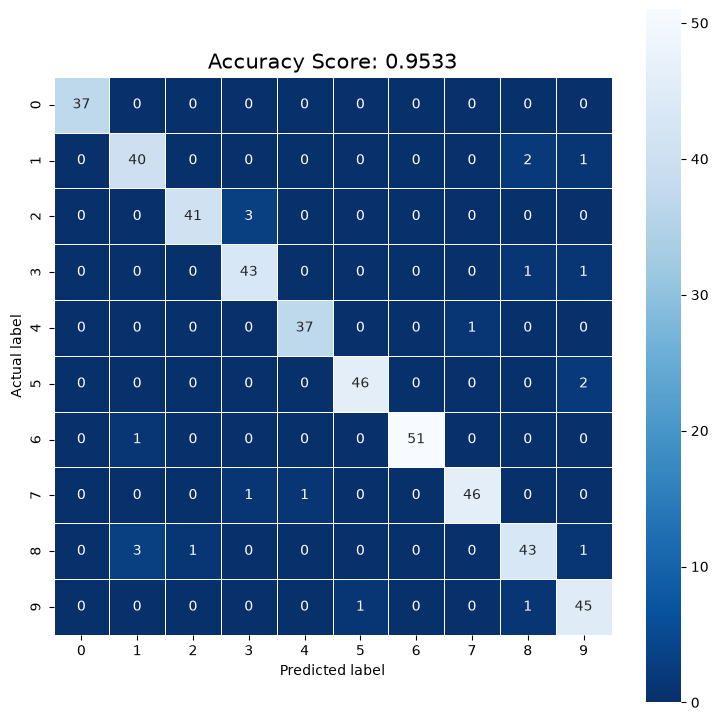

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

digits = load_digits()
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

logisticRegr = LogisticRegression(max_iter=10000)
logisticRegr.fit(x_train, y_train)
predictions = logisticRegr.predict(x_test)
score = logisticRegr.score(x_test, y_test)

cm = metrics.confusion_matrix(y_test, predictions)
print(cm)

plt.figure(figsize=(9, 9))
sns.heatmap(cm, annot=True, fmt=".0f", linewidths=.5, square=True, cmap="Blues_r")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Accuracy Score: {score:.4f}", size=15)
plt.show()

**Explanation:** The confusion matrix compares the actual digits (rows) with the predicted digits (columns). The diagonal holds correct predictions, and any number off the diagonal is a mistake.

**Show misclassified images**

Number of misclassified images: 21


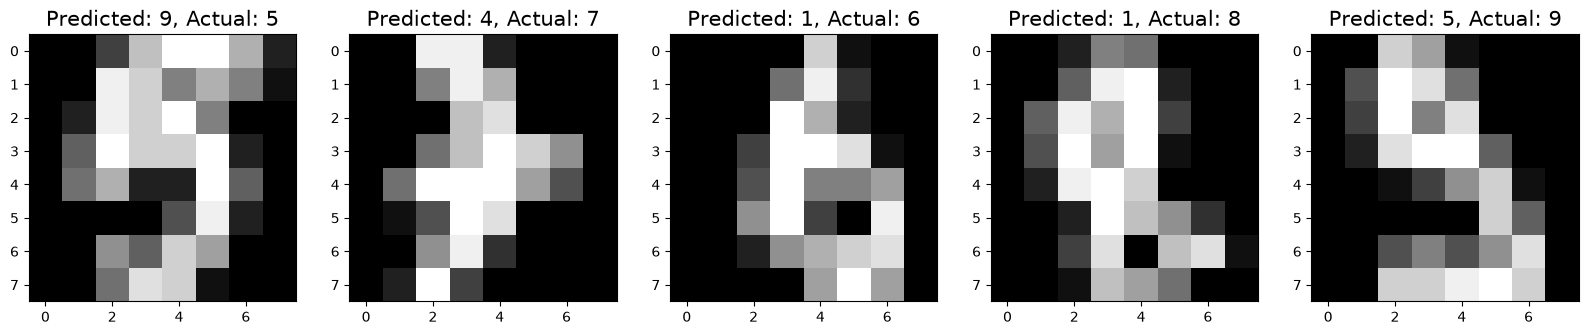

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

digits = load_digits()
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

logisticRegr = LogisticRegression(max_iter=10000)
logisticRegr.fit(x_train, y_train)
predictions = logisticRegr.predict(x_test)

misclassified = np.where(predictions != y_test)[0]
print("Number of misclassified images:", len(misclassified))

plt.figure(figsize=(20, 4))
for plot_index, bad_index in enumerate(misclassified[0:5]):
    plt.subplot(1, 5, plot_index + 1)
    plt.imshow(np.reshape(x_test[bad_index], (8, 8)), cmap=plt.cm.gray)
    plt.title(f"Predicted: {predictions[bad_index]}, Actual: {y_test[bad_index]}", fontsize=15)
plt.show()

**Explanation:** This finds the test images where the prediction was wrong and shows the first five, with the predicted and actual digits.

# Part 2 — Diabetes prediction (binary classification)

**Diagram:** What each cell of a 2 × 2 confusion matrix means.

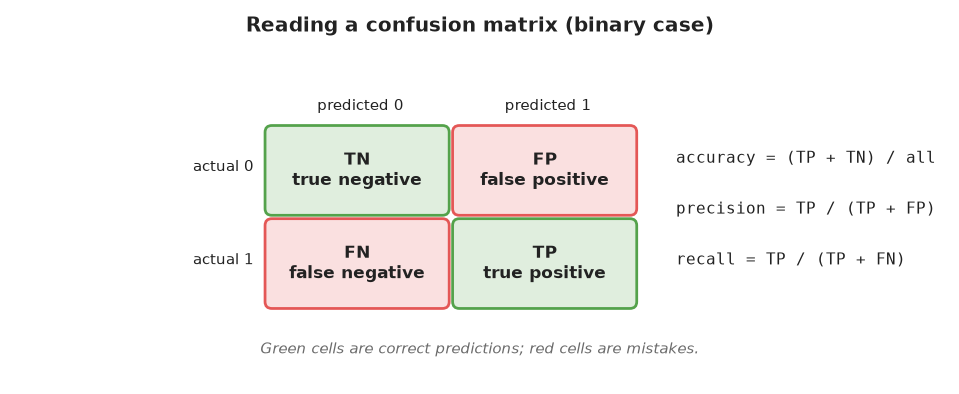

**Load the Pima Indians Diabetes data**

In [8]:
import pandas as pd

pima = pd.read_csv("diabetes.csv")

print(pima.head())
print(pima.shape)
print(pima["label"].value_counts())

   pregnant  glucose  bp  skin  insulin   bmi  pedigree  age  label
0         6      148  72    35        0  33.6     0.627   50      1
1         1       85  66    29        0  26.6     0.351   31      0
2         8      183  64     0        0  23.3     0.672   32      1
3         1       89  66    23       94  28.1     0.167   21      0
4         0      137  40    35      168  43.1     2.288   33      1
(768, 9)
label
0    500
1    268
Name: count, dtype: int64


**Explanation:** The data has 768 patients with 8 medical measurements each. label is 1 if the patient has diabetes and 0 if not, so this is a binary (two-class) problem.

**Select the features and split the data**

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

pima = pd.read_csv("diabetes.csv")

feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X = pima[feature_cols]
y = pima.label

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

print("Training rows:", len(X_train), "| test rows:", len(X_test))

Training rows: 576 | test rows: 192


**Explanation:** Seven features are used to predict the label. 75% of the rows train the model and 25% test it.

**Train the model and make predictions**

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X, y = pima[feature_cols], pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

logreg = LogisticRegression(random_state=16, max_iter=1000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual:     ", y_test.values[:10])
print("Probabilities of class 1:", logreg.predict_proba(X_test)[:5, 1].round(3))

First 10 predictions: [1 0 0 0 0 1 0 0 0 0]
First 10 actual:      [1 0 0 0 0 1 0 0 0 0]
Probabilities of class 1: [0.534 0.199 0.031 0.068 0.112]


**Explanation:** fit() learns one weight per feature. predict() returns the class, and predict_proba() returns the probability behind each prediction.

**Evaluate with a confusion matrix**

[[115  10]
 [ 25  42]]


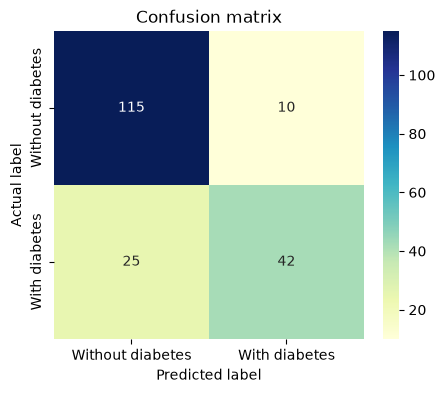

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X, y = pima[feature_cols], pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)
logreg = LogisticRegression(random_state=16, max_iter=1000).fit(X_train, y_train)
y_pred = logreg.predict(X_test)

cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
print(cnf_matrix)

plt.figure(figsize=(5, 4))
sns.heatmap(cnf_matrix, annot=True, fmt="d", cmap="YlGnBu",
            xticklabels=["Without diabetes", "With diabetes"], yticklabels=["Without diabetes", "With diabetes"])
plt.title("Confusion matrix")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.show()

**Explanation:** The diagonal holds the correct predictions. The off-diagonal cells show patients predicted wrongly in each direction.

**Classification report**

In [12]:
import pandas as pd
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X, y = pima[feature_cols], pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)
logreg = LogisticRegression(random_state=16, max_iter=1000).fit(X_train, y_train)
y_pred = logreg.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["without diabetes", "with diabetes"]))

                  precision    recall  f1-score   support

without diabetes       0.82      0.92      0.87       125
   with diabetes       0.81      0.63      0.71        67

        accuracy                           0.82       192
       macro avg       0.81      0.77      0.79       192
    weighted avg       0.82      0.82      0.81       192



**Explanation:** Precision is how many predicted diabetes cases were correct, and recall is how many real diabetes cases were found. The model is better at identifying patients without diabetes.

**ROC curve and AUC**

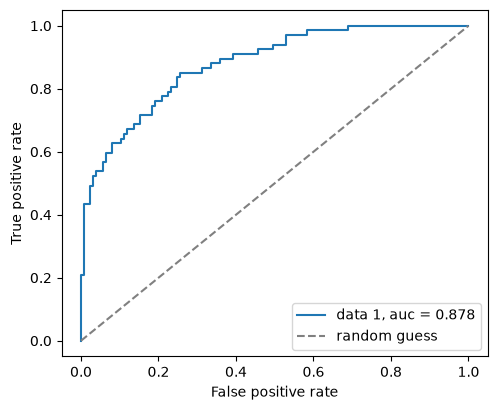

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X, y = pima[feature_cols], pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)
logreg = LogisticRegression(random_state=16, max_iter=1000).fit(X_train, y_train)

y_pred_proba = logreg.predict_proba(X_test)[:, 1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"data 1, auc = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc=4)
plt.show()

**Explanation:** The ROC curve shows the trade-off between finding real diabetes cases and raising false alarms at every probability threshold. The AUC (area under the curve) summarises it: 1 is perfect and 0.5 is no better than guessing.

## Observation

- Logistic regression predicts class probabilities with the sigmoid function and picks the most likely class.
- On the handwritten digits (10 classes) it reaches about 95% accuracy; the confusion matrix shows which digits get mixed up.
- On the diabetes data (2 classes) it is good at spotting patients without diabetes but misses some patients with diabetes, as recall shows.
- The confusion matrix, classification report and ROC/AUC each give a fuller picture than accuracy alone.

## Conclusion

Logistic regression is a simple, fast and interpretable classifier that works for both binary and multi-class problems. Evaluating it with several metrics shows not just how often it is right, but which mistakes it makes.